In [31]:
import numpy as pd
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.datasets import fetch_california_housing
%matplotlib inline

In [9]:
dataset= fetch_california_housing()
dataset.target

array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894])

In [14]:
dataset= fetch_california_housing()
df= pd.DataFrame(dataset.data, columns= dataset.feature_names)
df['MedhouseVal']= dataset.target
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedhouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [15]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedhouseVal'],
      dtype='object')

In [16]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedhouseVal,0


In [17]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedhouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [18]:
# in this exercise i am using medInc as independent variable and MedhouseVal as dependent variable

x= df[['MedInc']] # independent
y= df['MedhouseVal'] # dependent


#splitting the dataset for the training 80% train and 20% test
X_train, X_test, Y_train, Y_test= train_test_split(x,y,test_size=0.2,random_state=42)

print('X_train shape',X_train.shape[0])
print('-'*30)
print('X_test shape',X_test.shape[0])
print('-'*30)
print('Y_train shape',Y_train.shape[0])
print('-'*30)
print('Y_test shape',Y_test.shape[0])

X_train shape 16512
------------------------------
X_test shape 4128
------------------------------
Y_train shape 16512
------------------------------
Y_test shape 4128


In [19]:
#training of the simple Linear Regression Model

regressor= LinearRegression()
regressor.fit(X_train,Y_train)

print('intercept/bais:',regressor.intercept_)
print('slope/weight:',regressor.coef_)

intercept/bais: 0.4445972916907879
slope/weight: [0.41933849]


In [20]:
#therefore the linear equation is
print(f'y = {regressor.coef_}x + {regressor.intercept_}')

y = [0.41933849]x + 0.4445972916907879


In [24]:
#now predicting the test data

y_pred = regressor.predict(X_test)

predictions= pd.DataFrame({'Actual':Y_test, 'Predictated':y_pred})
predictions.head()


,Actual,Predictated
20046,0.47700,1.149589
3024,0.45800,1.506069
15663,5.00001,1.903937
20484,2.18600,2.850594
9814,2.78000,2.006633


In [25]:
#evaluating the model

mse= mean_squared_error(Y_test,y_pred)
rmse= root_mean_squared_error(Y_test,y_pred)
r2= r2_score(Y_test,y_pred)

print('Mean Squared Error:',mse)
print('-'*30)
print('Root Mean Squared Error:',rmse)
print('-'*30)
print('R2 Score:',r2)

Mean Squared Error: 0.7091157771765549
------------------------------
Root Mean Squared Error: 0.8420901241414455
------------------------------
R2 Score: 0.45885918903846656


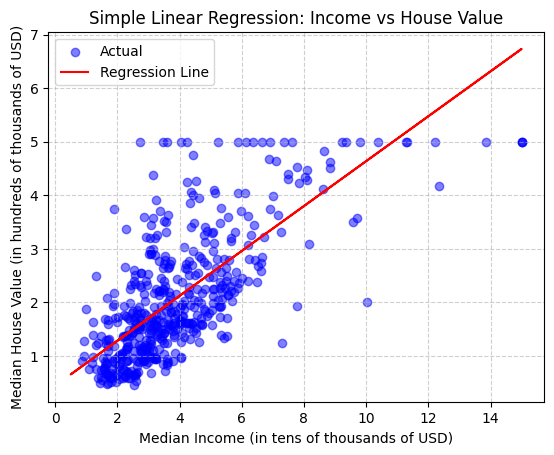

In [35]:
#plotting the graph
plt.scatter(X_test[:500],Y_test[:500], color='blue',alpha=0.5,label='Actual')

#plotting the  regression line
plt.plot(X_test,y_pred,color='red',label='Regression Line')


plt.title("Simple Linear Regression: Income vs House Value")
plt.xlabel("Median Income (in tens of thousands of USD)")
plt.ylabel("Median House Value (in hundreds of thousands of USD)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)